<a href="https://colab.research.google.com/github/lourrosaa/TP-Grupal-Analisis/blob/main/TP_analisis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#TRABAJO PRÁCTICO GRUPAL: Exploración, análisis y presentación de datos reales asistida por IA



---



*   Universidad de Buenos Aires - Facultad de Ciencias Económicas
* Tecnicatura Universitaria en Gestión y Análisis de Datos
*   *Asignatura*: Laboratorio de Métodos Cuantitativos Aplicados a la Gestión
*   *Período*: Segundo cuatrimestre 2026
* *Entrega*: 6 de noviembre de 2026



---


#Integrantes
(Nombre y apellido, N° de registro, Usuario de GitHub)


* Lourdes, Rosa-Larrieu - 921551 - "lourrosaa"
* Delfina, Colamónico Torres - 921509 - "dellll-ct"
* Clara, Trillini Montaron - 921538 - "claritatrillini"
* Melina Lais, Leiva - 921454 - "lainn7"



---




# Dataset: Sephora Website

* Fuente: https://www.kaggle.com/datasets/raghadalharbi/all-products-available-on-sephora-website


---


#Repositorio de Github:
 [ https://github.com/lourrosaa/TP-Grupal-Analisis.git ]


---





---


## Pregunta de investigación

**¿Cuál es la pregunta?**

¿Los productos de Edición Limitada consiguen en general más “Rating” (valoración) y más “Love” (popularidad) respecto a productos regulares entre los compradores de Sephora, o podemos concluir que quedarse con los productos clásicos es más rentable?

**¿Por qué vale la pena responderla?**

Las ediciones limitadas suelen presentarse como
productos especiales dentro del catálogo de
Sephora. Por este motivo, nos resulta interesante
analizar si esta característica se refleja en
una mayor valoración por parte de los consumidores
y en una mayor popularidad dentro de la plataforma. Nuestra idea de investigación nos permite comparar ambos tipos
de productos a partir de sus calificaciones
(Rating) y de la cantidad de favoritismo (Love),
identificando posibles diferencias en la percepción
y el interés que generan. Además, nos permitirá distinguir entre la valoración y la popularidad de los productos, dos aspectos
que no necesariamente presentan el mismo
comportamiento.

**¿Qué respuesta encontraron?**

A COMPLETARRRRRRRR

No logramos determinar qué tipo de producto resulta más rentable, debido a que los datos disponibles en el dataset no incluyen información sobre costos, ventas efectivas ni márgenes de ganancia.


---




Cargamos datos, importamos las librerias necesarias tanto para el analisis como para los graficos y la carga del arhivo CSV. Mostrando la informacion principal del Dataframe con las primeras y ultimas filas, cantidad de filas y columnas, datos vacios y filas repetidas. Printeamos cada cosa para que no ejecute solo el ultimo codigo que le pedimos.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

df = pd.read_csv("sephora_website_dataset.csv")
df.head()
print(df.head())
df.tail()
print(df.tail())
df.shape
print(df.shape)
df.dtypes
print(df.dtypes)
df.isnull().sum()
print(df.isnull().sum())

        id           brand   category                            name  \
0  2218774  Acqua Di Parma  Fragrance  Blu Mediterraneo MINIATURE Set   
1  2044816  Acqua Di Parma    Cologne                         Colonia   
2  1417567  Acqua Di Parma    Perfume                Arancia di Capri   
3  1417617  Acqua Di Parma    Perfume                Mirto di Panarea   
4  2218766  Acqua Di Parma  Fragrance           Colonia Miniature Set   

             size  rating  number_of_reviews  love  price  value_price  ...  \
0  5 x 0.16oz/5mL     4.0                  4  3002   66.0         75.0  ...   
1   0.7 oz/ 20 mL     4.5                 76  2700   66.0         66.0  ...   
2    5 oz/ 148 mL     4.5                 26  2600  180.0        180.0  ...   
3   2.5 oz/ 74 mL     4.5                 23  2900  120.0        120.0  ...   
4  5 x 0.16oz/5mL     3.5                  2   943   72.0         80.0  ...   

  MarketingFlags  MarketingFlags_content  \
0           True             online only  

Podemos ver que en este Dataset que importamos de Sephora ningun dato se encuentra vacio ademas de que la mayoria de datos son de texto o de numeros enteros, con solo pocas excepciones.

In [15]:
df[["limited_edition", "rating", "love"]].describe()
print(df[["limited_edition", "rating", "love"]].describe())
df["limited_edition"].value_counts()

       limited_edition       rating          love
count      9168.000000  9168.000000  9.168000e+03
mean          0.091841     3.990020  1.627859e+04
std           0.288817     1.007707  4.260651e+04
min           0.000000     0.000000  0.000000e+00
25%           0.000000     4.000000  1.600000e+03
50%           0.000000     4.000000  4.800000e+03
75%           0.000000     4.500000  1.380000e+04
max           1.000000     5.000000  1.300000e+06


,count
limited_edition,
0,8326
1,842


De los 9168 productos, solo 842 son de edicion limitada

In [16]:
df.groupby("limited_edition")["love"].median()


,love
limited_edition,
0,5000.0
1,3000.0


De los productos en total, se ve que los normales gustan mas que los productos de edicion limitada. Sin embargo tal vez eso no sea porque sean menos queridos por los compradores, se podria deber tambien a que al ser ediciones limitadas y durar menos tiempo en el mercado tienen menos tiempo para acumular "loves", no todos alcanzan a comprarlos o simplemente las personas prefieren los productos clasicos.

In [17]:
df_rating = df[df["rating"] > 0]
print(df_rating)
df_rating.groupby("limited_edition")["rating"].median()
print(df_rating.groupby("limited_edition")["rating"].median())
df_rating.groupby("limited_edition")["rating"].mean()
print(df_rating.groupby("limited_edition")["rating"].mean())

           id               brand                  category  \
0     2218774      Acqua Di Parma                 Fragrance   
1     2044816      Acqua Di Parma                   Cologne   
2     1417567      Acqua Di Parma                   Perfume   
3     1417617      Acqua Di Parma                   Perfume   
4     2218766      Acqua Di Parma                 Fragrance   
...       ...                 ...                       ...   
9160  2149847  SEPHORA COLLECTION  Bath Soaks & Bubble Bath   
9161  1601111  SEPHORA COLLECTION                Brush Sets   
9162  2149839  SEPHORA COLLECTION        Scrub & Exfoliants   
9163  2208502  SEPHORA COLLECTION                Face Masks   
9166       50  SEPHORA COLLECTION               no category   

                                                   name            size  \
0                        Blu Mediterraneo MINIATURE Set  5 x 0.16oz/5mL   
1                                               Colonia   0.7 oz/ 20 mL   
2                 

Aca vemos que no solo las ediciones limitadas tienen menos love que los productos normales, sino que tiene el mismo promedio de rating. Asi que por ahora no vemos que las ediciones limitadas gusten mas que las regulares. Despues lo confirmamos con los numeros exactos que da entre cada cosa.



---



## Transformación 1:
limpieza de valores sin datos reales ya que algunas columnas usan textos como "unknown" o "no category" para indicar que falta información. Se reemplazan por valores vacíos (NaN) para que no se interpreten como datos reales.

**Asistencia de IA (Claude):** la idea de esta transformación surgió de
una consulta a Claude. Prompt utilizado: "Busca a ver si hay inconsistencias o datos que tal vez esten vacios y no aparezcan como null pero que no sirvan y explicame si me sirve partir de eso para hacer una transformacion".
La IA detectó los textos "unknown", "no category" y "no size" en una tabla
que le compartió. Se verificó su presencia en el dataset
con value_counts() y explicó parte del código ya que hubo problemas con la deteccion de las inconsistencias del dataset, explico los prints y el uso del "df original" ya que se hayaron problemas iniciales en cuanto a la verificacion.

In [18]:
df_original = pd.read_csv("sephora_website_dataset.csv")

print("ingredients = unknown:", (df_original["ingredients"] == "unknown").sum())
print("category = no category:", (df_original["category"] == "no category").sum())
print("size = no size:", (df_original["size"] == "no size").sum())

df["ingredients"] = df["ingredients"].replace("unknown", np.nan)
df["category"] = df["category"].replace("no category", np.nan)
df["size"] = df["size"].replace("no size", np.nan)

df[["ingredients", "category", "size"]].isnull().sum()

ingredients = unknown: 1630
category = no category: 16
size = no size: 3161


,0
ingredients,1630
category,16
size,3161


Tras reemplazar los textos “unknown”, “no category” y “no size” por valores vacíos, se identificaron 364 productos sin ingredientes, 1 sin categoría y 715 sin tamaño. Estos valores se mantienen como datos faltantes y se excluyen de los análisis que dependan de esas columnas.


## Transformación 2: eliminacion de productos sin ninguna calificacion
Se quitan/excluyen los productos de rating 0, porque en realidad no se tratan de calificaciones de cero sino a productos
que nadie calificó todavía, conservarlos significaria bajar el promedio de rating y afecta la realidad del dato.

In [19]:
print("productos con rating 0: ", (df["rating"] == 0).sum())

productos con rating 0:  398




---


# Análisis de Gráficos

Realizamos tres gráficos que nos permiten complementar los resultados estadísticos obtenidos anteriormente, para analizar si los productos de edición limitada presentan mayor popularidad y mejor valoración que los productos normales de Sephora. Para facilitar la comparación de los productos según su tipo, separamos el DataFrame original en dos grupos: productos normales y productos de edición limitada. Esto nos permite analizar las variables de interés de manera independiente.

En primer lugar, comparamos la distribución de las valoraciones de ambos grupos. En segundo lugar, la cantidad mediana de favoritos de cada tipo de producto. Por último, analizamos la relación entre la cantidad de reseñas y la cantidad de favoritos registrados.

In [20]:
df_normal = df[df["limited_edition"] == 0]
df_limitado = df[df["limited_edition"] == 1]

# Primer Gráfico - Boxplot

**¿Los productos de edición limitada tienen mejor "Rating" que los productos normales?**

Para analizar si existen diferencias en la valoración
de los productos normales y de edición limitada, utilizamos un gráfico de tipo boxplot que nos permite comparar la mediana,
los cuartiles y la dispersión de las calificaciones de ambos grupos. Se considerarán únicamente los productos con una
calificación mayor a cero, excluyendo aquellos
registros que no presentan una valoración válida.

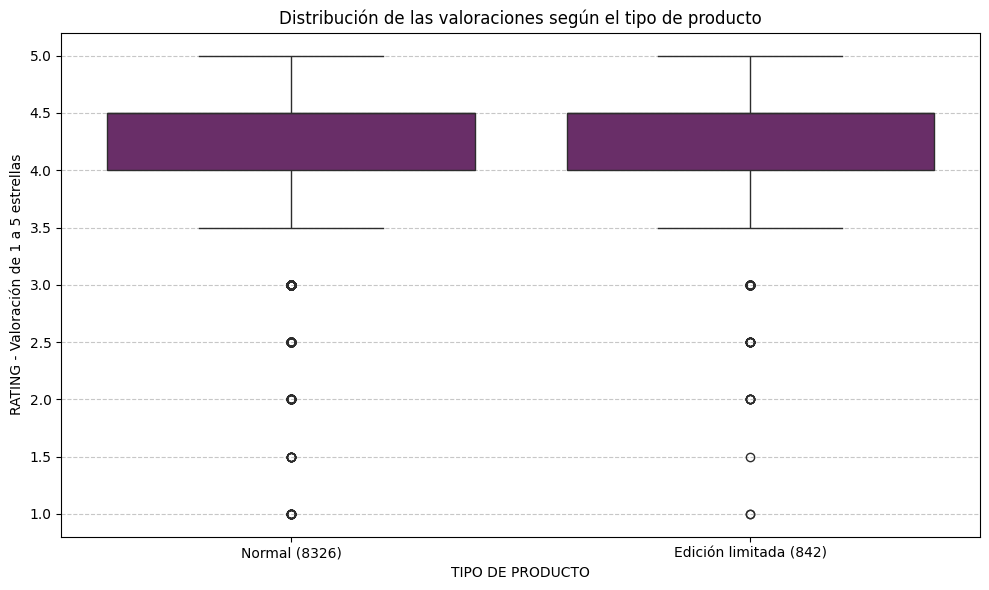

Porcentaje de calificaciones bajas (menor a 3.25):
Productos normales: 4.93 %
Productos limitados: 9.7 %


In [21]:
plt.figure(figsize=(10, 6))
sb.boxplot(x="limited_edition", y="rating", data=df_rating, color="#732472")
plt.title("Distribución de las valoraciones según el tipo de producto")
plt.xlabel("TIPO DE PRODUCTO")
plt.ylabel("RATING - Valoración de 1 a 5 estrellas")
plt.xticks([0, 1], ["Normal (8326)", "Edición limitada (842)"])
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()

plt.savefig("graf_boxplot_1.png", dpi=300)
plt.show()


#Investigación adicional para complementar el análisis del gráfico
ratings_normal = df_rating[df_rating["limited_edition"] == 0]["rating"]
ratings_limitados = df_rating[df_rating["limited_edition"] == 1]["rating"]
cantidad_bajas_normal = (ratings_normal < 3.25).sum()
cantidad_bajas_limitados = (ratings_limitados < 3.25).sum()
porcentaje_normal = cantidad_bajas_normal / len(ratings_normal) * 100
porcentaje_limitados = cantidad_bajas_limitados / len(ratings_limitados) * 100

print("Porcentaje de calificaciones bajas (menor a 3.25):")
print("Productos normales:", round(porcentaje_normal, 2), "%")
print("Productos limitados:", round(porcentaje_limitados, 2), "%")


# Análisis Gráfico 1

El gráfico nos permite comparar la distribución de las
calificaciones de los productos normales y de edición
limitada. Podemos observar que ambos grupos presentan una
mediana de 4,5 estrellas y los mismos cuartiles, por
lo que no identificamos diferencias en su valoración
central. Sin embargo, al hacer una investigación complementaria al gráfico y calcular las proporciones, se demuestra que entre los productos de edición limitada hay un mayor porcentaje de calificaciones bajas (contemplando calificaciones menores a 3.25). Esto indica que, aunque el gráfico muestra que ambos grupos tienen una valoración central similar, las ediciones limitadas tienen casi el doble de calificaciones bajas (9,7 %, frente a 4,9 % en los productos normales).

En conclusión, este primer análisis nos muestra que los productos de edición limitada tienen una mayor proporción de calificaciones ubicadas por debajo del límite inferior establecido por el boxplot.


    Asistencia de IA (ChatGPT): En esta parte de la investigación se utilizó IA con la intención de expandir el análisis de los resultados del gráfico, para esto le pedimos a la misma que nos ayude a trabajar con algún dato extra del dataset relacionado al objetivo de este primer gráfico. Como consecuencia, nos recomendó agregar el cálculo de proporciones. PROMPT UTILIZADO: "Dado el gráfico creado para este proyecto compartido, quisiera que me digas si hay algun cálculo estadístico que pueda complementar el análisis del mismo"

# Segundo Gráfico - Barras

**¿Los productos de edición limitada tienen más "Love" que los productos normales?**

Para analizar la popularidad de los productos
normales y de edición limitada, realizamos un
gráfico de barras que nos permite comparar la mediana
de favoritos (Love) de cada grupo. Usamos la mediana porque en lo que repecta la popularidad hay valores muy altos que distorsionan el promedio. De esta manera nos permite representar mejor el valor
central de cada grupo, y la comparación nos permite identificar qué tipo de producto registra una mayor cantidad de "Love"
por producto.

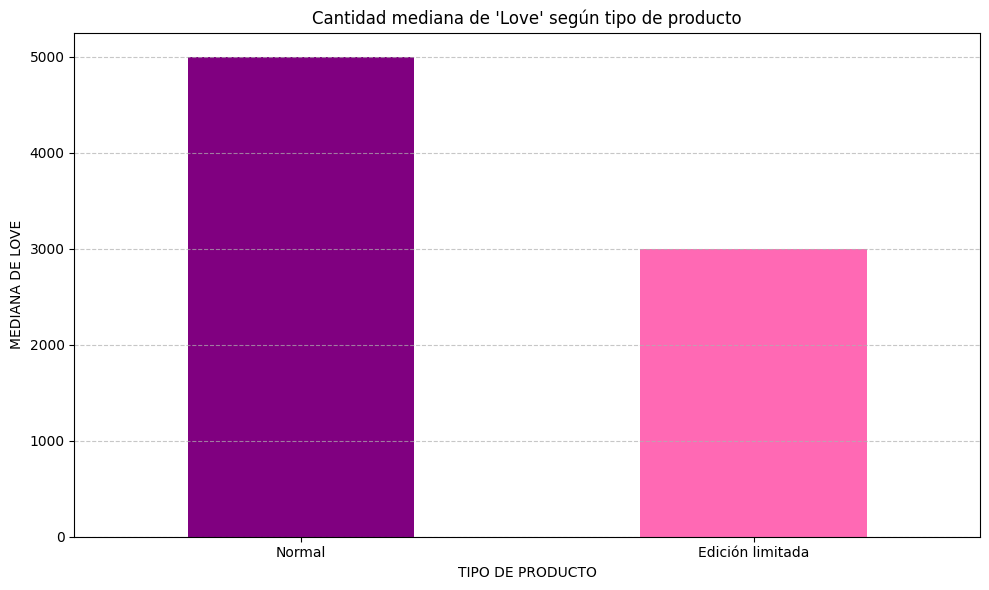

In [22]:
love_mediana = df.groupby("limited_edition")["love"].median()
plt.figure(figsize=(10, 6))
love_mediana.plot(kind="bar", color=["purple", "hotpink"])
plt.title("Cantidad mediana de 'Love' según tipo de producto")
plt.xlabel("TIPO DE PRODUCTO")
plt.ylabel("MEDIANA DE LOVE")
plt.xticks([0, 1], ["Normal", "Edición limitada"], rotation=0)
plt.ticklabel_format(style="plain", axis="y")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()

plt.savefig("graf_barras_2.png", dpi=300)
plt.show()

# Análisis Gráfico 2

El gráfico nos muestra que los productos del catalogados como "normales" presentan una mediana de Love superior
a la de los productos de edición limitada. Mientras que los productos normales registran una mediana de 5.000 favoritos, los productos limitados presentan una mediana de 3.000. Esto nos indica que, dentro de todo el catálogo analizado, los productos normales tienen una mayor cantidad central de popularidad por producto. De cualquier manera, este resultado no nos permite afirmar que los consumidores prefieran necesariamente los
productos normales, ya que factores como el tiempo
de permanencia en el catálogo o la exposición de
cada producto pueden influir en su sumatoria de popularidad.

# Tercer Gráfico - Dispersión

**¿Los productos que tienen más reseñas también suelen tener más "Love"?**

Para complementar el análisis de popularidad, realizamos un diagrama de disperción que nos permite
estudiar la relación entre la cantidad de reseñas
y la cantidad de "Love" de los productos. Cada punto representa un producto del dataset que usamos, y diferenciamos los productos normales de los de edición limitada para facilitar la comparación
entre ambos grupos. Nuestro objetivo es identificar si existe una relación entre estas dos variables y observar los patrones que puedan aportar información sobre la popularidad
de los productos.


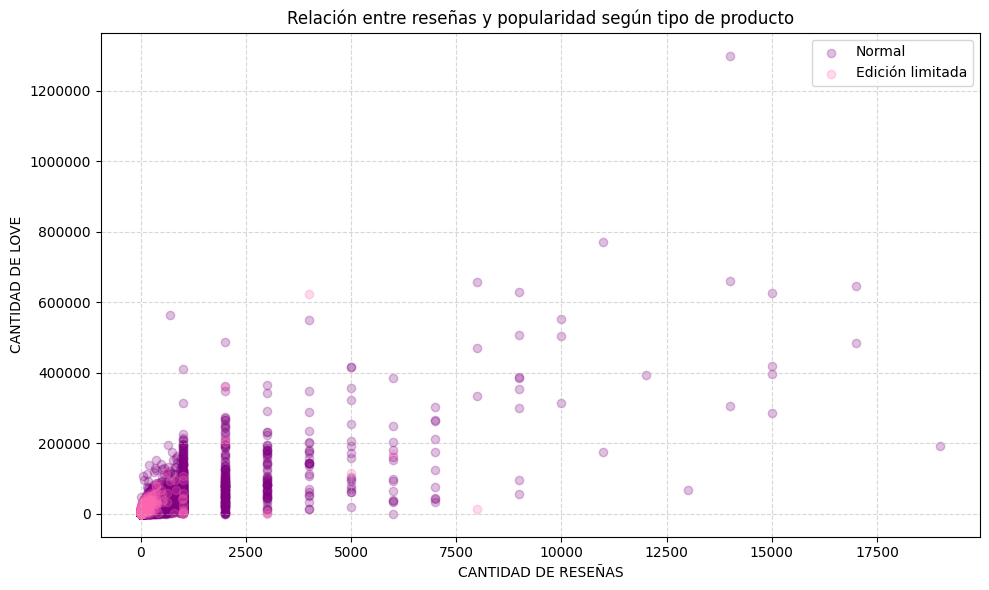

TODOS LOS PRODUCTOS
Pearson: 0.746
Spearman: 0.824
PRODUCTOS NORMALES
Pearson: 0.754
Spearman: 0.83
PRODUCTOS DE EDICIÓN LIMITADA
Pearson: 0.538
Spearman: 0.845


In [23]:

plt.figure(figsize=(10, 6))
plt.scatter(
    df_normal["number_of_reviews"],
    df_normal["love"],
    color="purple",
    label="Normal",
    alpha=0.25)
plt.scatter(
    df_limitado["number_of_reviews"],
    df_limitado["love"],
    color="hotpink",
    label="Edición limitada",
    alpha=0.25)
plt.title("Relación entre reseñas y popularidad según tipo de producto")
plt.xlabel("CANTIDAD DE RESEÑAS")
plt.ylabel("CANTIDAD DE LOVE")
plt.legend()
plt.ticklabel_format(style="plain", axis="y")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig("graf_dispersion_3.png", dpi=300)
plt.show()


# Investigación adicional para complementar el análisis del gráfico
# PEARSON
pearson_total = df["number_of_reviews"].corr(
    df["love"], method="pearson"
)
pearson_normal = df_normal["number_of_reviews"].corr(
    df_normal["love"], method="pearson"
)
pearson_limitado = df_limitado["number_of_reviews"].corr(
    df_limitado["love"], method="pearson"
)
# SPEARMAN
spearman_total = df["number_of_reviews"].corr(
    df["love"], method="spearman"
)
spearman_normal = df_normal["number_of_reviews"].corr(
    df_normal["love"], method="spearman"
)
spearman_limitado = df_limitado["number_of_reviews"].corr(
    df_limitado["love"], method="spearman"
)

print("TODOS LOS PRODUCTOS")
print("Pearson:", round(pearson_total, 3))
print("Spearman:", round(spearman_total, 3))
print("PRODUCTOS NORMALES")
print("Pearson:", round(pearson_normal, 3))
print("Spearman:", round(spearman_normal, 3))
print("PRODUCTOS DE EDICIÓN LIMITADA")
print("Pearson:", round(pearson_limitado, 3))
print("Spearman:", round(spearman_limitado, 3))


# Análisis Gráfico 3

El gráfico nos permite observar una asociación positiva entre la cantidad de reseñas y la cantidad de popularidad (Love) de los productos. En general, los productos que registran más reseñas también tienden a presentar una mayor cantidad de "Love", lo que indica que ambas variables funcionan como complementarias de la interacción y popularidad dentro del dataset.

Para profundizar este análisis, hicimos una investigación complementaria al gráfico donde  calculamos los coeficientes de correlación de Pearson y Spearman. Considerando el conjunto total de productos, se obtuvieron valores de 0,746 para Pearson y 0,824 para Spearman, lo que evidencia una asociación positiva entre ambas variables desde las dos perspectivas. Al analizar los grupos por separado, los productos normales presentan correlaciones de 0,754 según Pearson y 0,830 según Spearman. En los productos de edición limitada, los valores son de 0,538 y 0,845, respectivamente.

La diferencia entre ambos coeficientes en las ediciones limitadas sugiere que, aunque existe una relación monotónica marcada entre las variables, no se manifiesta con la misma intensidad en términos de relación lineal. Lo que puede estar relacionado con la presencia de valores extremos, que influyen especialmente en la correlación de Pearson. Spearman, al trabajar con el orden de los valores, resulta menos sensible a las magnitudes extremas.

En conclusión, los resultados nos indican que la cantidad de reseñas y de favoritos presenta una asociación positiva en ambos grupos, aunque su intensidad y comportamiento varían según el tipo de producto. Sin embargo, esta relación no permite afirmar que una mayor cantidad de reseñas provoque necesariamente un aumento de "Love".


    Asistencia de IA(ChatGPT): En esta parte de la investigación se utilizó IA con la intención de expandir el análisis de los resultados del gráfico, para esto le pedimos a la misma que nos ayude a trabajar con algún dato extra del dataset relacionado al objetivo de este tercer gráfico. Como consecuencia, nos recomendó utilizar y calcular los coeficiente de correlación de Pearson y Spearman. PROMPT UTILIZADO: "Dado el gráfico creado para este proyecto compartido, quisiera que me digas si hay algun cálculo estadístico que pueda complementar el análisis del mismo"
---

